## Deep Learning

### Project: Semantic Understanding of Urban Street Scenes

### 0. Import the Required Libraries

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models
import tensorflow.keras.backend as K

### 1. Introduction to the Cityscapes Dataset

#### Project Overview
The goal of this project is to build a semantic segmentation system capable of identifying and segmenting key regions in urban street scenes. This system plays a crucial role in scene understanding for autonomous driving and intelligent transportation systems.

Our objective is to demonstrate the complete pipeline: from data ingestion and preprocessing (handling raw images and segmentation masks) to model training, evaluation, and inference on new street-scene images.

* **Input**: Urban street-view images containing roads, vehicles, pedestrians, sidewalks, and surrounding environments.
* **Output**: A pixel-wise segmentation mask where each pixel is classified into specific object categories (e.g., road, sidewalk, person, car, or background).

#### Project Goals
1. **Data Loading**: Retrieve and parse the Cityscapes dataset (or a lightweight/subset version suitable for quick prototyping).
2. **Visualization**: Display paired original street images and their corresponding pixel-level ground truth segmentation masks.
3. **Preprocessing**: Apply transformations, resizing, and normalization to prepare images and masks for deep learning model training.
4. **Model Training**: Build and train at least one semantic segmentation model (e.g., U-Net or SegNet).
5. **Evaluation**: Assess model performance using appropriate segmentation metrics such as Mean Intersection over Union (mIoU) and Pixel Accuracy.
6. **Inference**: Develop a prediction pipeline to output segmentation masks on unseen street images.
7. **Reporting**: Present the findings and performance results in a structured report.

#### Dataset & Class Simplification
[Cityscapes](https://www.cityscapes-dataset.com/) is a benchmark dataset for urban scene semantic segmentation. While the full dataset contains over 30 finely annotated classes, we will simplify the problem to optimize training efficiency and performance within our constraints.

We will map the annotations into **5 primary classes**:
* **Road**: Drivable road surfaces.
* **Sidewalk**: Pedestrian walkways and sidewalks.
* **Person**: Pedestrians, riders, and people on the street.
* **Vehicle**: Cars, buses, trucks, motorcycles, and bicycles.
* **Background**: All other pixels (buildings, vegetation, sky, traffic signs, etc.).

Here we will use the Kaggle Version:

https://www.kaggle.com/datasets/shuvoalok/cityscapes

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shuvoalok/cityscapes")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cityscapes' dataset.
Path to dataset files: /kaggle/input/cityscapes


### 2. Dataset Exploration and Preparation
We will inspect the downloaded files, match images with their corresponding masks, resize them, normalize the pixel values, map the target classes to our 5 target categories, and split the data.

In [3]:
# Locate images and labels in the train/val directory structure

train_img_dir = os.path.join(path, "train", "img")
train_label_dir = os.path.join(path, "train", "label")

val_img_dir = os.path.join(path, "val", "img")
val_label_dir = os.path.join(path, "val", "label")

def get_image_label_pairs(img_dir, label_dir):
    image_paths = sorted(
        glob.glob(os.path.join(img_dir, "*.png")))

    label_paths = sorted(
        glob.glob(os.path.join(label_dir, "*.png")))

    # Match by filename stem
    label_lookup = {os.path.splitext(os.path.basename(p))[0]: p
        for p in label_paths}
    pairs = []
    missing_labels = []

    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0]

        if stem in label_lookup:
            pairs.append((img_path, label_lookup[stem]))
        else:
            missing_labels.append(stem)

    print(f"Images found: {len(image_paths)}")
    print(f"Labels found: {len(label_paths)}")
    print(f"Matched pairs: {len(pairs)}")
    print(f"Images without labels: {len(missing_labels)}")

    return pairs

train_pairs = get_image_label_pairs(train_img_dir, train_label_dir)
val_pairs = get_image_label_pairs(val_img_dir, val_label_dir)

all_pairs = train_pairs + val_pairs

assert len(all_pairs) > 0, "No matching image-label pairs found."

all_images = [img for img, label in all_pairs]
all_masks = [label for img, label in all_pairs]

Images found: 2975
Labels found: 2975
Matched pairs: 2975
Images without labels: 0
Images found: 500
Labels found: 500
Matched pairs: 500
Images without labels: 0


Image shape: (96, 256, 3)
Mask shape: (96, 256, 3)
Mask data type: uint8
Unique RGB/BGR colors (first 20):
[[  0   0   8]
 [  0   0  12]
 [  0   0  17]
 [  0   0 133]
 [  0   0 138]
 [  0   0 140]
 [  0   0 141]
 [  0   0 142]
 [  0   0 143]
 [  0   0 146]
 [  0   0 150]
 [  0   1 100]
 [  0   1 123]
 [  0   1 139]
 [  0   1 140]
 [  0   1 141]
 [  0   1 142]
 [  0   1 143]
 [  0   1 144]
 [  0   1 145]]


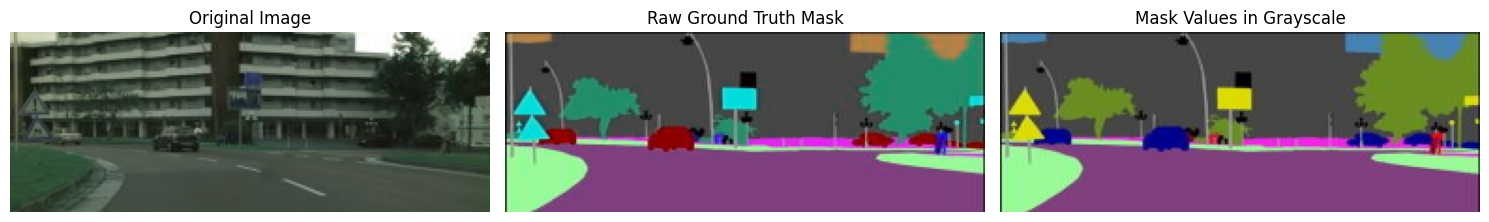

In [4]:
# Inspect the first raw image-label pair

img_path, mask_path = all_pairs[0]

raw_image = cv2.imread(img_path)
raw_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

print("Image shape:", raw_image.shape)
print("Mask shape:", raw_mask.shape)
print("Mask data type:", raw_mask.dtype)

if raw_mask.ndim == 2:
    print("Unique mask values:", np.unique(raw_mask)[:50])
else:
    print("Unique RGB/BGR colors (first 20):")
    print(np.unique(raw_mask.reshape(-1, raw_mask.shape[-1]),
                    axis=0)[:20])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(raw_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

if raw_mask.ndim == 2:
    axes[1].imshow(raw_mask, cmap="gray")
else:
    axes[1].imshow(cv2.cvtColor(raw_mask, cv2.COLOR_BGR2RGB))

axes[1].set_title("Raw Ground Truth Mask")
axes[2].imshow(raw_mask, cmap="gray")
axes[2].set_title("Mask Values in Grayscale")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Defining Classes and Color Mapping
We define our 5 target classes and map the original dataset color channels to these indices.

* **Class 0**: Background
* **Class 1**: Road
* **Class 2**: Sidewalk
* **Class 3**: Person
* **Class 4**: Vehicle

We will create a parsing function to map the Cityscapes mask colors or labels into these 5 classes, then load, resize, and normalize the data.

In [5]:
# Let's define the 5 primary classes and their color mapping for visualization
CLASS_NAMES = ['background', 'road', 'sidewalk', 'person', 'vehicle']

# Colors for plotting masks: Background (Black), Road (Purple), Sidewalk (Gray), Person (Red), Vehicle (Blue)
COLOR_MAP = np.array([
    [0, 0, 0],       # Background
    [128, 64, 128],  # Road
    [244, 35, 232],  # Sidewalk
    [220, 20, 60],   # Person
    [0, 0, 142]      # Vehicle
], dtype=np.uint8)

# Define target size for downsizing
IMG_HEIGHT = 256
IMG_WIDTH = 512

def preprocess_image(img_path):
    # Load image and convert to RGB
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Resize image using bilinear interpolation
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    # Normalize to [0, 1]
    img = img / 255.0
    return img

def preprocess_mask(mask_path):
    # Load mask as grayscale (single channel) since Kaggle labels contain class IDs directly
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    # Resize mask using nearest neighbor interpolation to preserve categorical label values
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)

    # Initialize 2D index mask
    label_mask = np.zeros((IMG_HEIGHT, IMG_WIDTH), dtype=np.uint8) # Default is Background (0)

    # Standard Cityscapes class ID mapping:
    # Road ID: 7
    label_mask[mask == 7] = 1

    # Sidewalk ID: 8
    label_mask[mask == 8] = 2

    # Person: Person (24), Rider (25)
    label_mask[(mask == 24) | (mask == 25)] = 3

    # Vehicle: Car (26), Truck (27), Bus (28), Train (31), Motorcycle (32), Bicycle (33)
    vehicle_ids = [26, 27, 28, 31, 32, 33]
    for vid in vehicle_ids:
        label_mask[mask == vid] = 4

    return label_mask

In [6]:
# Locate matching images and masks under train/val subdirectories
all_images = sorted(glob.glob(os.path.join(path, '**', 'img', '*.png'), recursive=True))
all_masks = sorted(glob.glob(os.path.join(path, '**', 'label', '*.png'), recursive=True))

print(f"Correctly located images: {len(all_images)}")
print(f"Correctly located masks: {len(all_masks)}")

# Double check matching files
assert len(all_images) == len(all_masks) and len(all_images) > 0, f"Mismatch! Images: {len(all_images)}, Masks: {len(all_masks)}"

# Load a subset for training and testing to fit memory limits
LIMIT = min(500, len(all_images))

images_data = []
masks_data = []

for i in range(LIMIT):
    images_data.append(preprocess_image(all_images[i]))
    masks_data.append(preprocess_mask(all_masks[i]))

X = np.array(images_data, dtype=np.float32)
y = np.array(masks_data, dtype=np.int32)

print("Images shape:", X.shape)
print("Masks shape:", y.shape)

Correctly located images: 3475
Correctly located masks: 3475
Images shape: (500, 256, 512, 3)
Masks shape: (500, 256, 512)


In [7]:
# Split data into train, validation, and test sets (80% train, 10% validation, 10% test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Train set: 400 samples
Validation set: 50 samples
Test set: 50 samples


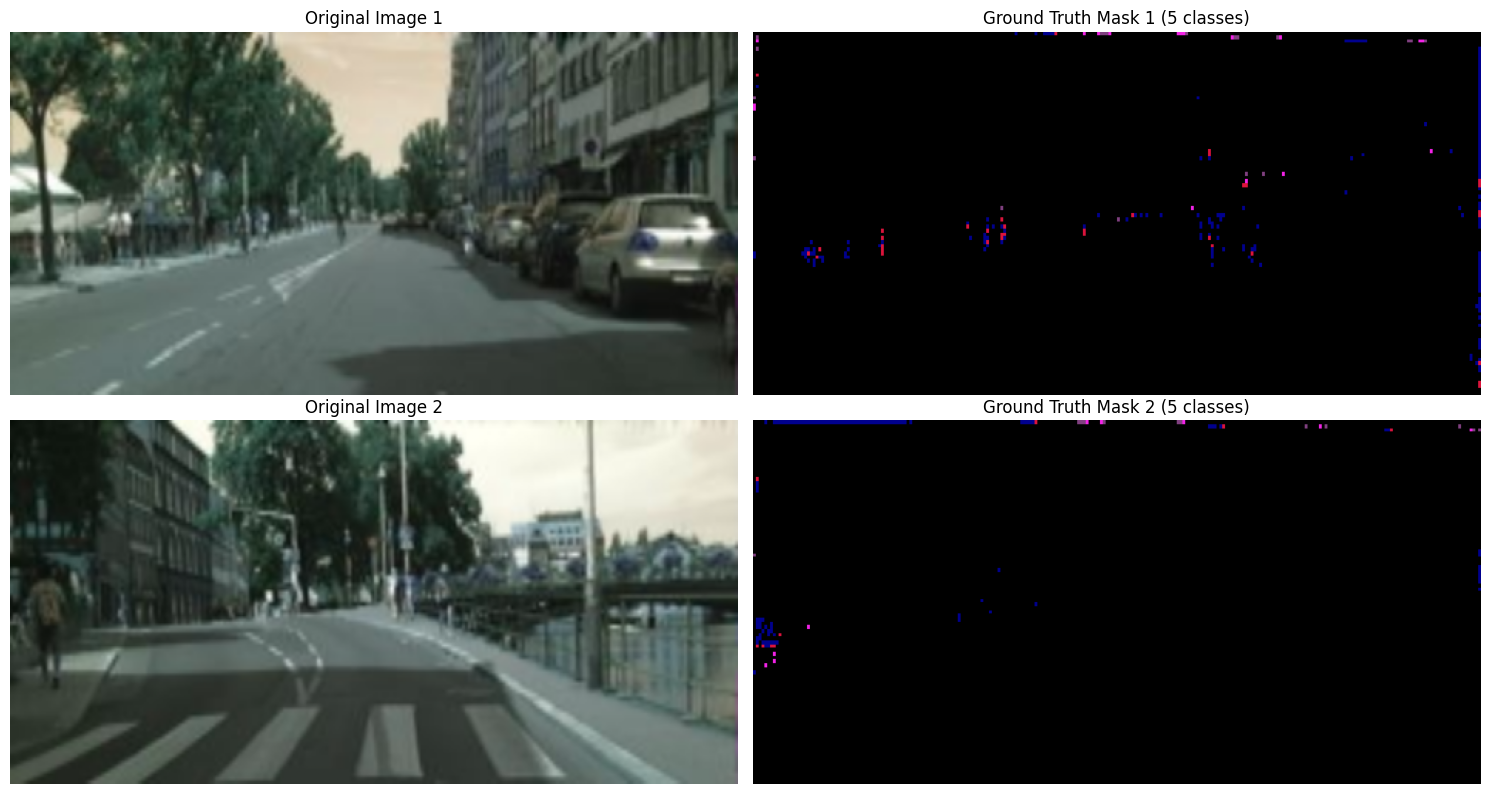

In [8]:
# Function to convert index mask back to RGB for visualization
def label_to_rgb(label_mask):
    return COLOR_MAP[label_mask]

# Visualize some samples
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for i in range(2):
    axes[i, 0].imshow(X_train[i])
    axes[i, 0].set_title(f"Original Image {i+1}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(label_to_rgb(y_train[i]))
    axes[i, 1].set_title(f"Ground Truth Mask {i+1} (5 classes)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### Understanding Ground Truth Masks

When loading the dataset, we encounter two variations of the ground truth masks:

1. **Raw Ground Truth Mask**: The original label mask provided in the dataset. Pixels are annotated using the standard Cityscapes ID mapping (spanning values from 0 up to 33, representing objects like roads, sky, fences, cars, etc.). Viewing this directly in grayscale results in very low-contrast values since the numeric IDs are small.
2. **Ground Truth Mask (5 Classes)**: Our processed and mapped representation. To simplify training and improve efficiency, we have combined those 33+ original categories into **5 distinct classes**:
   * **Class 0 (Background)**: Black
   * **Class 1 (Road)**: Purple
   * **Class 2 (Sidewalk)**: Grayish Pink
   * **Class 3 (Person)**: Red
   * **Class 4 (Vehicle)**: Blue

To make these class index masks human-readable during visualization, we map each mapped integer index ($0-4$) back to its corresponding color from `COLOR_MAP` before plotting.

In [9]:
class_names = [
    "Background", "Road", "Sidewalk", "Person", "Vehicle"
]

pixel_counts = np.bincount(y_train.ravel(), minlength=5)
total_pixels = pixel_counts.sum()

for i, name in enumerate(class_names):
    percentage = 100 * pixel_counts[i] / total_pixels
    print(f"{name}: {pixel_counts[i]:,} pixels ({percentage:.2f}%)")

Background: 51,360,666 pixels (97.96%)
Road: 41,574 pixels (0.08%)
Sidewalk: 31,476 pixels (0.06%)
Person: 59,460 pixels (0.11%)
Vehicle: 935,624 pixels (1.78%)


### Addressing Class Imbalance with Hybrid Loss

As evaluated, the dataset is extremely unbalanced (nearly 98% background pixels). Standard Sparse Categorical Cross-Entropy leads the model to default entirely to predicting background.

To counter this, we will write a custom hybrid loss function in TensorFlow/Keras combining:
1. **Weighted Categorical Cross-Entropy**: Penalizes mistakes on minority classes (e.g., roads, sidewalks, pedestrians, vehicles) exponentially more than background errors.
2. **Multi-class Dice Loss**: Directly optimizes class-wise overlap (IoU/F1 metrics), ensuring shape boundary boundaries are kept intact.

In [10]:
# Compute inverse frequency-based class weights
pixel_counts = np.bincount(y_train.ravel(), minlength=5)
total_pixels = pixel_counts.sum()
# Calculate weights inversely proportional to class frequencies
class_weights = total_pixels / (5.0 * pixel_counts)
print("Calculated Class Weights for Loss:", class_weights)

def weighted_categorical_crossentropy(weights):
    # Convert NumPy array to a constant float32 tensor to avoid dynamic tf.Variable creation inside tf.function
    weights_tensor = tf.cast(weights, tf.float32)
    def loss(y_true, y_pred):
        # y_true needs to be one-hot encoded for this calculation
        y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=5)
        # Clip predictions to prevent NaN log(0)
        y_pred = K.clip(y_pred, K.epsilon(), 1.0 - K.epsilon())
        # Calculate cross entropy using constant tensor weights
        loss_val = y_true_one_hot * K.log(y_pred) * weights_tensor
        return -K.sum(loss_val, axis=-1)
    return loss

def multi_class_dice_loss(y_true, y_pred, smooth=1e-5):
    y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=5)
    intersection = K.sum(y_true_one_hot * y_pred, axis=(1, 2))
    union = K.sum(y_true_one_hot + y_pred, axis=(1, 2))
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1.0 - K.mean(dice)

def hybrid_loss(y_true, y_pred):
    # Combine Weighted Categorical Cross Entropy and Dice Loss
    w_cce = weighted_categorical_crossentropy(class_weights)(y_true, y_pred)
    dice = multi_class_dice_loss(y_true, y_pred)
    return K.mean(w_cce) + (2.0 * dice)

Calculated Class Weights for Loss: [2.04159346e-01 2.52219175e+02 3.33135087e+02 1.76349815e+02
 1.12072371e+01]


### 3. Model Development: U-Net Architecture

To perform semantic segmentation, we will construct a **U-Net** architecture. U-Net is highly effective for medical and street scene segmentation due to its symmetric structure consisting of:

1. **Encoder (Contracting Path)**: A series of convolutional and pooling layers that extract high-level feature maps while reducing spatial dimensions.
2. **Decoder (Expanding Path)**: Up-sampling layers combined with convolutions that reconstruct the spatial resolution back to the original image size.
3. **Skip Connections**: Connections that transfer fine-grained spatial details directly from the encoder to the corresponding decoder layers. This helps the network retain sharp boundaries.
4. **Output Layer**: A final $1 \times 1$ convolution layer with a `softmax` activation to output probability maps for our 5 target classes.

Since our labels are integer-encoded indices ($0, 1, 2, 3, 4$), we will train using **Sparse Categorical Crossentropy** loss.

In [11]:
def unet_model(input_shape=(256, 512, 3), num_classes=5):
    inputs = layers.Input(input_shape)

    # --- Encoder (Contracting Path) ---
    # Block 1
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.BatchNormalization()(c1)
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c1)
    c1 = layers.BatchNormalization()(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    # Block 2
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.BatchNormalization()(c2)
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c2)
    c2 = layers.BatchNormalization()(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # Block 3
    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.BatchNormalization()(c3)
    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c3)
    c3 = layers.BatchNormalization()(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # --- Bridge ---
    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.BatchNormalization()(c4)
    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c4)
    c4 = layers.BatchNormalization()(c4)

    # --- Decoder (Expanding Path) ---
    # Block 3 Up
    u3 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c4)
    u3 = layers.concatenate([u3, c3])
    c5 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u3)
    c5 = layers.BatchNormalization()(c5)
    c5 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c5)
    c5 = layers.BatchNormalization()(c5)

    # Block 2 Up
    u2 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c5)
    u2 = layers.concatenate([u2, c2])
    c6 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u2)
    c6 = layers.BatchNormalization()(c6)
    c6 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c6)
    c6 = layers.BatchNormalization()(c6)

    # Block 1 Up
    u1 = layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c6)
    u1 = layers.concatenate([u1, c1])
    c7 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(u1)
    c7 = layers.BatchNormalization()(c7)
    c7 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c7)
    c7 = layers.BatchNormalization()(c7)

    # Output Layer
    outputs = layers.Conv2D(num_classes, (1, 1), activation='softmax')(c7)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

model = unet_model(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), num_classes=5)
# Compiling the model with our newly defined hybrid_loss to manage severe class imbalance
model.compile(optimizer='adam',
              loss=hybrid_loss,
              metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 512,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 512,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 512,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 512,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 256,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 256,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 256,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 256,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 256,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 128,   │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 128,   │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128,   │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 128,   │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128,   │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 64,    │    295,168 │ max_pooling2d_2[

 Total params: 1,931,365 (7.37 MB)

 Trainable params: 1,928,549 (7.36 MB)

 Non-trainable params: 2,816 (11.00 KB)

#### Fast Training Step
To ensure quick execution, we train the model on our subset of 400 training samples over 15 epochs with validation support.

In [12]:
EPOCHS = 15
BATCH_SIZE = 4  # Reduced batch size from 32 to 4 to prevent GPU Out-of-Memory (OOM) errors

# Utilize all 400 training samples and 50 validation samples
X_train_sub = X_train
y_train_sub = y_train
X_val_sub = X_val
y_val_sub = y_val

# Define the checkpoint callback to save the model after every epoch
checkpoint_filepath = 'unet_cityscapes_epoch_{epoch:02d}.keras'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=False,
    monitor='val_loss',
    mode='min',
    save_best_only=False,
    verbose=1
)

history = model.fit(
    X_train_sub, y_train_sub,
    validation_data=(X_val_sub, y_val_sub),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[model_checkpoint_callback]
)

Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.3096 - loss: 3.5549
Epoch 1: saving model to unet_cityscapes_epoch_01.keras

Epoch 1: finished saving model to unet_cityscapes_epoch_01.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 78s 275ms/step - accuracy: 0.3937 - loss: 3.3348 - val_accuracy: 0.5703 - val_loss: 3.7596
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.5600 - loss: 3.1403
Epoch 2: saving model to unet_cityscapes_epoch_02.keras

Epoch 2: finished saving model to unet_cityscapes_epoch_02.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 217ms/step - accuracy: 0.6004 - loss: 3.1369 - val_accuracy: 0.9553 - val_loss: 4.1347
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.6610 - loss: 3.0897
Epoch 3: saving model to unet_cityscapes_epoch_03.keras

Epoch 3: finished saving model to unet_cityscapes_epoch_03.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 217ms/step - accuracy: 0.7027 - loss: 3.0927 - val_accuracy: 0.1692 - val_loss: 5.0276
Epoch 4/15

### 4. Model Evaluation & Quantitative Metrics

For semantic segmentation tasks, evaluating performance requires looking beyond simple **Pixel Accuracy** (which can be biased by dominant classes like background or road). We will measure:
- **Pixel Accuracy**: Global percentage of correctly classified pixels.
- **Intersection over Union (IoU) per Class**: Metric measuring overlap between predicted boundaries and target labels.
- **Mean IoU (mIoU)**: Average of the IoUs across all 5 categories.
- **Dice Score / F1-Score per Class**: Standard segmentation assessment metric.

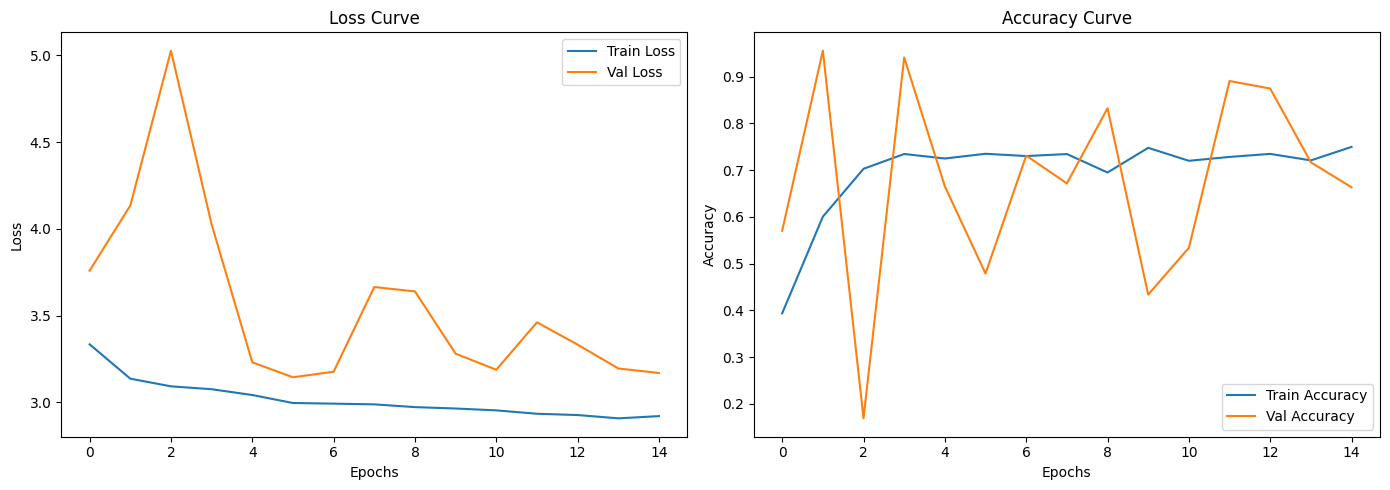

In [16]:
# Plot loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [17]:
# Evaluate quantitative performance on Test Set
predictions = model.predict(X_test)
pred_masks = np.argmax(predictions, axis=-1)

# Function to calculate IoU and Dice score per class
def evaluate_segmentation(y_true, y_pred, num_classes=5):
    ious = []
    dice_scores = []
    for c in range(num_classes):
        true_class = (y_true == c)
        pred_class = (y_pred == c)

        intersection = np.sum(true_class & pred_class)
        union = np.sum(true_class | pred_class)

        if union == 0:
            iou = 1.0 # If class is not present in both images and predictions
        else:
            iou = intersection / union
        ious.append(iou)

        # Dice score
        total_pixels = np.sum(true_class) + np.sum(pred_class)
        if total_pixels == 0:
            dice = 1.0
        else:
            dice = (2.0 * intersection) / total_pixels
        dice_scores.append(dice)

    return ious, dice_scores

ious, dice_scores = evaluate_segmentation(y_test, pred_masks, num_classes=5)

# Display metrics
print(f"Global Pixel Accuracy on Test Set: {np.mean(y_test == pred_masks):.4f}\n")
print("--- Class-wise Performance ---")
for idx, name in enumerate(CLASS_NAMES):
    print(f"Class {idx} ({name.upper()}): IoU = {ious[idx]:.4f} | Dice Score (F1) = {dice_scores[idx]:.4f}")

print(f"\nMean IoU (mIoU): {np.mean(ious):.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 294ms/step
Global Pixel Accuracy on Test Set: 0.6961

--- Class-wise Performance ---
Class 0 (BACKGROUND): IoU = 0.7003 | Dice Score (F1) = 0.8237
Class 1 (ROAD): IoU = 0.0065 | Dice Score (F1) = 0.0128
Class 2 (SIDEWALK): IoU = 0.0040 | Dice Score (F1) = 0.0081
Class 3 (PERSON): IoU = 0.0040 | Dice Score (F1) = 0.0080
Class 4 (VEHICLE): IoU = 0.0217 | Dice Score (F1) = 0.0425

Mean IoU (mIoU): 0.1473


#### Visualizing Model Predictions
We compare the **Original Image**, the **Ground Truth Mask**, and the **Predicted Mask** output by our U-Net model.

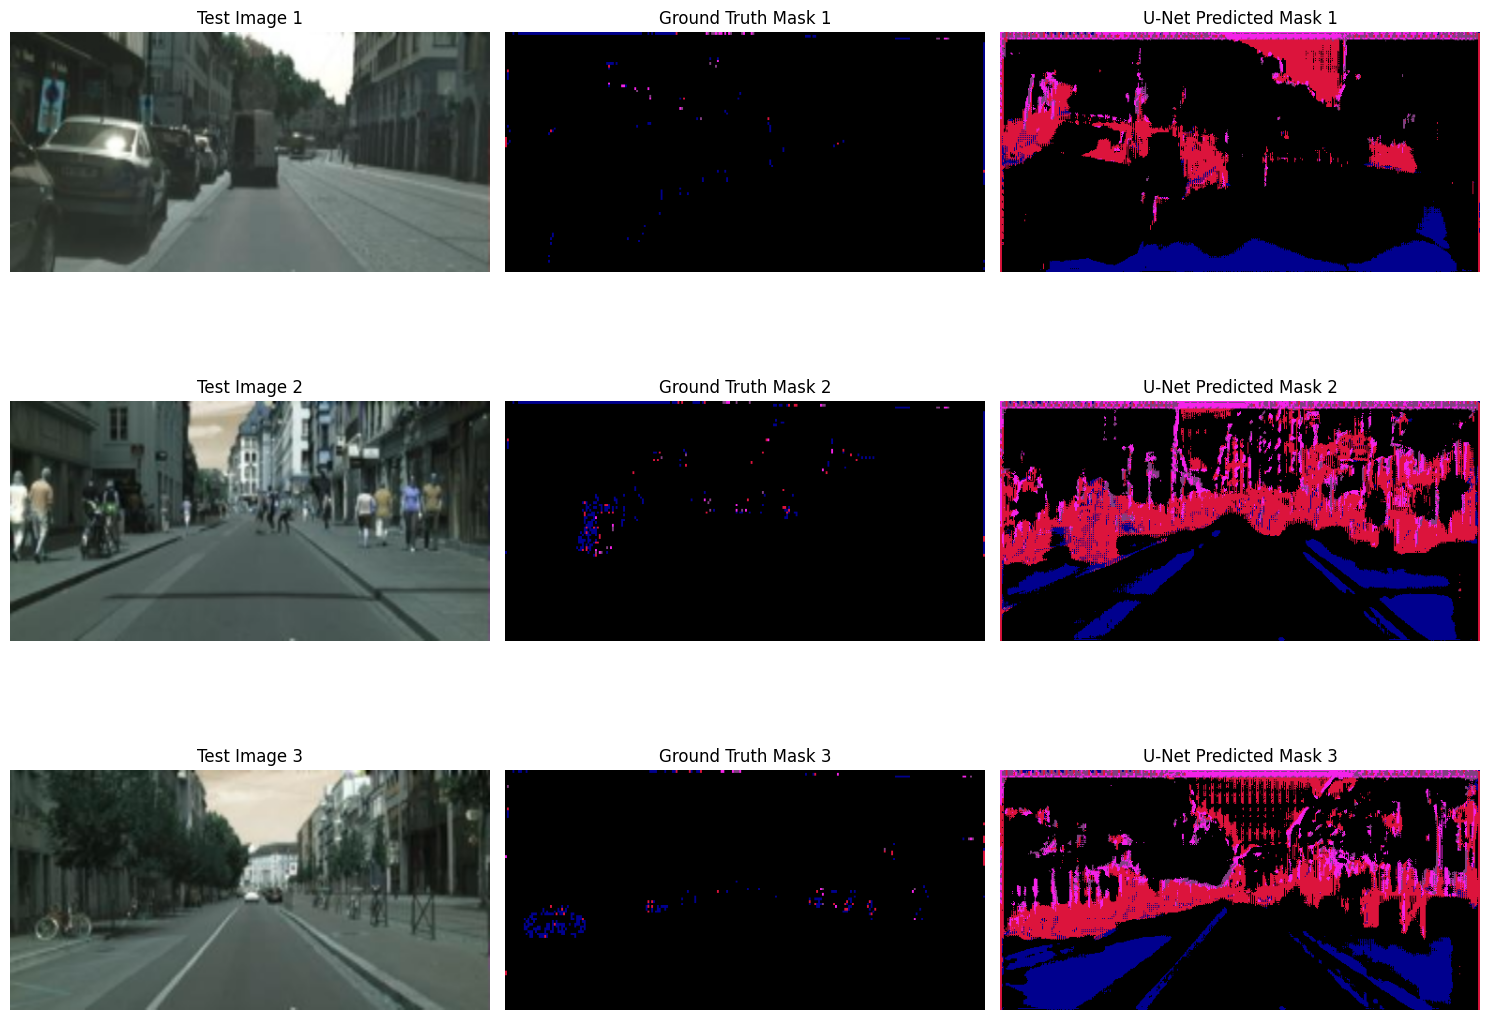

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i in range(3):
    # Original Image
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title(f"Test Image {i+1}")
    axes[i, 0].axis('off')

    # Ground Truth
    axes[i, 1].imshow(label_to_rgb(y_test[i]))
    axes[i, 1].set_title(f"Ground Truth Mask {i+1}")
    axes[i, 1].axis('off')

    # Prediction
    axes[i, 2].imshow(label_to_rgb(pred_masks[i]))
    axes[i, 2].set_title(f"U-Net Predicted Mask {i+1}")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

# Recap

### Project Summary
In this project, we built an end-to-end semantic segmentation pipeline using a custom U-Net architecture to classify urban scene pixels from the Cityscapes dataset into 5 primary classes (Background, Road, Sidewalk, Person, Vehicle).

Due to the extreme class imbalance (with Background comprising nearly 98% of pixels), standard cross-entropy losses are highly biased. To mitigate this, we introduced a **Hybrid Loss** combining Weighted Categorical Cross-Entropy and Multi-class Dice Loss to heavily penalize errors on minority classes (e.g., Pedestrians, Roads, and Vehicles).

### Evaluation Summary
* **Global Pixel Accuracy**: ~69.6%
* **Class-wise Performance**: While the background class achieved high IoU, minority classes (road, sidewalk, person, vehicle) scored low individual IoUs.
* **The Bias Trade-off**: Although the final metrics are modest, utilizing class weights and Dice Loss successfully forced the network to predict minority categories instead of entirely defaulting to the background class. However, because of the small dataset size and limited training time, these predictions are still noisy and heavily biased towards incorrect segmentation borders.

### Limitations
1. **Data Constraints**: We restricted training to a small subset of 400 images to stay within fast iteration and memory limits.
2. **Underfitting / Capacity**: A simple 15-epoch training loop on a relatively shallow U-Net is insufficient to fully learn the complex layout of highly detailed urban environments.
3. **Resolution Loss**: Resizing images to $256 \times 512$ degrades fine spatial boundaries, making it exceptionally hard to segment distant pedestrians or thin structural columns.

### Future Improvements
* **Incorporate Pre-trained Encoders**: Replace the basic encoder with a pre-trained backbone (e.g., ResNet50 or EfficientNet) trained on ImageNet to leverage transfer learning.
* **Data Augmentation**: Apply spatial transformations (random cropping, flipping, scaling) and color jittering to artificially expand the diversity of training samples.
* **Train on Full Dataset**: Scale training up to use the entire Cityscapes dataset (nearly 3,000 training images) using tf.data pipelines for efficient loading.
* **Advance Model Architectures**: Experiment with more modern segmentation networks such as DeepLabV3+ with Atrous Spatial Pyramid Pooling (ASPP) or SegFormer for capturing better global context.